# RF 기준 딥러닝 비교 — 사전학습·미세조정·RF결합

학습 전에 고정하는 비교 설계

RF기준은기존동일분할의누락59/오탐272입니다. 사용자선택에맞춰RF를기준모델로유지하고,픽셀기반전이학습이추가개선할수있는지확인합니다.

- 원본이미지분할을그대로사용: 학습7540 / 검증2514 / 기존홀드아웃2514장. 같은원본이분할사이에섞이지않습니다.
- 입력은회색조800×128로원본종횡비와전체시야를유지합니다. 중심crop으로작은결함을지우지않습니다.
- 사전학습ResNet18에서평균+최대풀링1024특징을추출하고선형분류기를학습해기준선을만듭니다.
- 다음으로후반두블록과분류헤드를미세조정합니다. 이진BCE에클래스1~4존재여부의보조손실을추가합니다. 정답마스크를픽셀입력에넣지않습니다.
- 학습증강은좌우/상하반전과약한밝기·대비변화입니다. 무작위crop은사용하지않습니다.
- **주선택기준:** 검증RF오탐262장(정상1180장중22.20%)이내에서재현율최대, 동률은AP→낮은FP. 체크포인트도이기준으로선택합니다.
- **보조운영점:** 기존처럼검증recall95%이상의가장높은임계값.
- 최대12epoch,4epoch개선없으면조기종료. 검증만사용하고기존홀드아웃은선택후비교합니다.
- 좌우반전평균(TTA)과CNN비중25/50/75%의RF결합을미리정의해검증에서비교합니다.
- 픽셀해상도와학습감독(클래스보조손실)도다르므로개선이있어도아키텍처만의효과로단정하지않습니다.
- 기존홀드아웃을이미관찰한후속실험입니다. 새로운맹검평가는아닙니다.

공식참고: [ResNet18](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet18.html), [전이학습](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial), [MPS](https://docs.pytorch.org/docs/main/notes/mps.html).

# 1. 실행 환경

PyCharm 프로젝트의Python환경을사용합니다. MPS가가능하면MacGPU에서실제학습합니다. 학습·데이터처리는모두이노트북커널안에서수행하며DataLoader는`num_workers=0`입니다.

In [5]:
# 환경 확인: 학습은 이 노트북 커널에서 직접 실행합니다.
from pathlib import Path
import os,sys,json,platform,random,time
os.environ.setdefault('LOKY_MAX_CPU_COUNT','4')
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK','1')
PROJECT=Path('/Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main')
DATA_DIR=PROJECT.parent
OUT=PROJECT/'deep_learning_outputs'
OUT.mkdir(exist_ok=True)
if str(PROJECT) not in sys.path:
    sys.path.insert(0,str(PROJECT))
import numpy as np
import pandas as pd
import torch,torchvision,psutil
from IPython.display import display,Image as DisplayImage
from threadpoolctl import threadpool_limits
numeric_threads=threadpool_limits(limits=4)
torch.set_num_threads(4)
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
DEVICE='cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('Python:',sys.executable)
print('PyTorch:',torch.__version__,'torchvision:',torchvision.__version__)
print('장치:',DEVICE,'| 전체RAM GB:',round(psutil.virtual_memory().total/2**30,1),'| 사용가능RAM GB:',round(psutil.virtual_memory().available/2**30,1))
print('출력:',OUT)

Python: /Users/yeongjunna/Projects/.venv/bin/python
PyTorch: 2.15.0 torchvision: 0.29.2
장치: mps | 전체RAM GB: 16.0 | 사용가능RAM GB: 3.7
출력: /Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main/deep_learning_outputs


## 2. 동일한 이미지 분할과 고해상도 입력

기존ML실험의이미지분할·RF모델을읽습니다. RF만분리한파일을사용해Torch와다른부스팅런타임의충돌을피합니다. 모든입력이미지의해시를기존분할표와대조하고,원본비율그대로800×128회색조캐시를만듭니다.

In [6]:
import test1_deep_learning as dl
data_dl=dl.prepare(PROJECT,DATA_DIR,OUT)
display(data_dl['manifest'].groupby('split').has_defect.agg(images='size',defect='sum'))
print('RF검증기준:',data_dl['rf_validation_metrics'])
print('검증FP상한:',data_dl['fp_budget'])
print('입력캐시:',data_dl['cache'].shape)
print('학습설정:',json.dumps(data_dl['config'],ensure_ascii=False,indent=2))

,images,defect
split,,
holdout,2514,1333
train,7540,3999
validation,2514,1334


RF검증기준: {'recall': 0.9505247376311844, 'precision': 0.8287581699346406, 'f1': 0.8854748603351955, 'accuracy': 0.8695306284805091, 'fpr': 0.22203389830508474, 'flagged_rate': 0.6085918854415274, 'tp': 1268, 'fn': 66, 'fp': 262, 'tn': 918, 'ap': 0.9524048695494604, 'roc_auc': 0.9497325489797473}
검증FP상한: 262
입력캐시: (12568, 128, 800)
학습설정: {
  "seed": 42,
  "input_width_height": [
    800,
    128
  ],
  "batch_size": 12,
  "max_epochs": 12,
  "patience": 4,
  "backbone": "ImageNet-pretrained ResNet18",
  "pool": "global average + global maximum (1024 features)",
  "finetune": "layer3,layer4,binary head,auxiliary4class head; freeze BatchNorm statistics",
  "augmentation": "horizontal/vertical flips, mild brightness/contrast; no random crop",
  "objective": "binary BCE + .25 weighted multilabel BCE",
  "validation_selection": "maximum recall at FP<=RF validation FP; ties AP then fewer FP",
  "validation_fp_budget": 262,
  "secondary_policy": "validation recall>=.95 highest cutoff",
  "fusion

## 3. 사전학습CNN 특징 기준선

ImageNet 사전학습ResNet18의특징맵에서전체평균과최댓값을결합해1024개특징을얻습니다. 학습·검증이미지에서만추출하고학습세트로표준화·로지스틱회귀를맞춥니다. 이를미세조정의분류헤드초기값으로사용해무작위초기화보다안정적으로출발합니다. 홀드아웃은아직평가하지않습니다.

In [7]:
# 학습·검증의사전학습CNN특징만추출합니다. 홀드아웃에는아직예측하지않습니다.
frozen_metrics=dl.benchmark_and_features(data_dl)
print('고정CNN특징+선형분류기 검증:',frozen_metrics)

사전학습 특징추출 256/10,054 | 1.0초
사전학습 특징추출 512/10,054 | 2.0초
사전학습 특징추출 768/10,054 | 2.9초
사전학습 특징추출 1,024/10,054 | 3.8초
사전학습 특징추출 1,280/10,054 | 4.7초
사전학습 특징추출 1,536/10,054 | 5.7초
사전학습 특징추출 1,792/10,054 | 6.6초
사전학습 특징추출 2,048/10,054 | 7.5초
사전학습 특징추출 2,304/10,054 | 8.5초
사전학습 특징추출 2,560/10,054 | 9.4초
사전학습 특징추출 2,816/10,054 | 10.4초
사전학습 특징추출 3,072/10,054 | 11.3초
사전학습 특징추출 3,328/10,054 | 12.3초
사전학습 특징추출 3,584/10,054 | 13.2초
사전학습 특징추출 3,840/10,054 | 14.2초
사전학습 특징추출 4,096/10,054 | 15.1초
사전학습 특징추출 4,352/10,054 | 16.1초
사전학습 특징추출 4,608/10,054 | 17.1초
사전학습 특징추출 4,864/10,054 | 18.0초
사전학습 특징추출 5,120/10,054 | 19.0초
사전학습 특징추출 5,376/10,054 | 20.0초
사전학습 특징추출 5,632/10,054 | 21.0초
사전학습 특징추출 5,888/10,054 | 22.0초
사전학습 특징추출 6,144/10,054 | 23.0초
사전학습 특징추출 6,400/10,054 | 23.9초
사전학습 특징추출 6,656/10,054 | 24.9초
사전학습 특징추출 6,912/10,054 | 25.8초
사전학습 특징추출 7,168/10,054 | 26.8초
사전학습 특징추출 7,424/10,054 | 27.7초
사전학습 특징추출 7,680/10,054 | 28.6초
사전학습 특징추출 7,936/10,054 | 29.5초
사전학습 특징추출 8,192/10,054 | 30.5초
사전학습 특징추출 8,448/10,054 |

## 4. 실제CNN 미세조정

ResNet18의layer3·layer4와분류헤드를학습합니다. 앞부분과BatchNorm통계는고정해소배치의분포흔들림을줄입니다. 이진정답과클래스별존재여부보조손실을사용합니다. optimizer는AdamW,후반블록학습률1e-4/헤드5e-4,cosine감쇠·gradient clipping을적용합니다.

매epoch에학습손실과검증AP·RF동일FP상한의recall을기록합니다. 최대12epoch,4epoch검증개선이없으면중단합니다. 홀드아웃은체크포인트선택에사용하지않습니다.

In [10]:
import importlib
importlib.reload(dl)
# 완료된 학습기록과 체크포인트가 있으면 복원합니다. 새로 학습하려면 force_retrain=True.
training_history = dl.finetune(data_dl)
display(training_history)
print('검증으로 선택한 epoch:', data_dl['best_epoch'])

완료된 학습 복원: 9epoch 기록 / 검증 선택epoch 5


,epoch,loss,epoch_seconds,validation_recall_at_rf_fp,validation_precision_at_rf_fp,validation_fp,validation_fn,validation_ap,validation95_precision,validation95_fp
0,1,0.533125,69.568547,0.981259,0.834289,260,25,0.971270,0.886713,162
1,2,0.344706,67.042928,0.980510,0.838462,252,26,0.982448,0.904422,134
2,3,0.274098,66.265713,0.990255,0.847882,237,13,0.987218,0.942751,77
3,4,0.224866,67.841938,0.991754,0.844828,243,11,0.989199,0.946975,71
4,5,0.179008,65.806268,0.996252,0.840076,253,5,0.992833,0.969419,40
5,6,0.148821,66.932480,0.990255,0.837136,257,13,0.991716,0.967201,43
6,7,0.122158,68.914086,0.995502,0.837855,257,6,0.990808,0.969419,40
7,8,0.092996,66.834394,0.992504,0.852543,229,10,0.993441,0.975385,32
8,9,0.071341,66.872425,0.994753,0.853376,228,7,0.994180,0.976135,31


검증으로 선택한 epoch: 5


## 5. 검증에서 CNN·TTA·RF결합과 운영점 선택

학습이끝난뒤검증에서만사전학습CNN기준선·미세조정CNN·좌우반전평균을비교합니다. 고정CNN과미세조정CNN 각각을RF와25/50/75%비중으로결합해상호보완가능성도확인합니다.

주운영점은RF검증오탐262장이내에서recall최대인점입니다. 보조운영점두개는①검증recall95% ②RF검증오탐예산의75%(196장)입니다. 보수적예산은실제평가오탐을보장하지않으며세운영점모두평가를보기전에동결합니다.

모델선택·체크포인트·임계값은전부검증에서정합니다. 아래표의FP는**검증오탐**이며최종평가의FP와구별합니다.

In [11]:
importlib.reload(dl)
validation_candidates,frozen_operating_points=dl.select_validation_candidates(data_dl)
display(validation_candidates[['candidate','split','threshold','recall','precision','ap','fn','fp']])
display(frozen_operating_points)
print('검증으로동결한딥러닝후보:',data_dl['selected_deep_candidate'])

전체후보와세운영점동결. 선택딥러닝후보: CNN_finetuned_TTA


,candidate,split,threshold,recall,precision,ap,fn,fp
0,RandomForest,validation,0.381440,0.950525,0.828758,0.952405,66,262
1,CNN_frozen_features,validation,0.121460,0.966267,0.832150,0.975957,45,260
2,CNN_finetuned,validation,0.026206,0.996252,0.840076,0.992833,5,253
3,CNN_finetuned_TTA,validation,0.053468,0.997001,0.863076,0.993892,4,211
4,RF_frozenCNN_25pct,validation,0.336199,0.981259,0.836957,0.973616,25,255
5,RF_frozenCNN_50pct,validation,0.275024,0.982009,0.834395,0.978467,24,260
6,RF_frozenCNN_75pct,validation,0.187234,0.974513,0.833868,0.978750,34,259
7,RF_finetunedCNN_25pct,validation,0.307851,0.993253,0.835962,0.980645,9,260
8,RF_finetunedCNN_50pct,validation,0.314232,0.994003,0.898374,0.987898,8,150
9,RF_finetunedCNN_75pct,validation,0.141791,0.996252,0.851377,0.990702,5,232


,candidate,policy,threshold
0,RandomForest,RF_same_FP_budget,0.381440
1,RandomForest,recall95,0.381440
2,RandomForest,RF_FP_budget75pct,0.454568
3,CNN_frozen_features,RF_same_FP_budget,0.121460
4,CNN_frozen_features,recall95,0.234840
5,CNN_frozen_features,RF_FP_budget75pct,0.234382
6,CNN_finetuned,RF_same_FP_budget,0.026206
7,CNN_finetuned,recall95,0.854312
8,CNN_finetuned,RF_FP_budget75pct,0.059061
9,CNN_finetuned_TTA,RF_same_FP_budget,0.053468


검증으로동결한딥러닝후보: CNN_finetuned_TTA


## 6. 같은 기존홀드아웃에서 RF와 비교

선택을끝낸후기존평가2514장에적용합니다. RF평가59FN/272FP가재현되는지다시확인합니다. 아래표는**평가오탐·누락**입니다. 주운영점과보조운영점을모두보고하되평가값으로모델이나임계값을다시고르지않습니다.

클래스별결과는각유형이미지에결함경보가울린비율입니다. 4종유형예측의정확도나픽셀분할점수가아닙니다. 이번은픽셀정보·다중작업학습도활용한실제파이프라인비교이며아키텍처만의통제실험은아닙니다.

In [12]:
holdout_candidates,holdout_class_alarm=dl.evaluate_holdout(data_dl)
display(holdout_candidates[['candidate','policy','split','recall','precision','f1','ap','fn','fp']])
print('검증선택후보의주평가결과:')
print(data_dl['main_result'].to_string())
print('기존RF비교:',data_dl['rf_result'].to_dict())
print('두오류모두개선했는지:',data_dl['dominates_rf_counts'])
print('판정변화:',data_dl['effects'])
print('딥러닝−RF 재현율차이95%구간:',data_dl['recall_difference_ci'])

동결후홀드아웃추론: 고정CNN특징
동결후홀드아웃추론: 미세조정CNN/좌우반전


,candidate,policy,split,recall,precision,f1,ap,fn,fp
0,RandomForest,RF_same_FP_budget,holdout,0.955739,0.824062,0.885030,0.950060,59,272
1,RandomForest,recall95,holdout,0.955739,0.824062,0.885030,0.950060,59,272
2,RandomForest,RF_FP_budget75pct,holdout,0.921230,0.866620,0.893091,0.950060,105,189
3,CNN_frozen_features,RF_same_FP_budget,holdout,0.982746,0.827543,0.898491,0.979923,23,273
4,CNN_frozen_features,recall95,holdout,0.972993,0.871640,0.919532,0.979923,36,191
5,CNN_frozen_features,RF_FP_budget75pct,holdout,0.972993,0.871640,0.919532,0.979923,36,191
6,CNN_finetuned,RF_same_FP_budget,holdout,0.997749,0.836478,0.910024,0.992558,3,260
7,CNN_finetuned,recall95,holdout,0.957989,0.967424,0.962684,0.992558,56,43
8,CNN_finetuned,RF_FP_budget75pct,holdout,0.995499,0.867320,0.927000,0.992558,6,203
9,CNN_finetuned_TTA,RF_same_FP_budget,holdout,0.996999,0.861309,0.924200,0.993047,4,214


검증선택후보의주평가결과:
candidate       CNN_finetuned_TTA
policy          RF_same_FP_budget
split                     holdout
threshold                0.053468
recall                   0.996999
precision                0.861309
f1                         0.9242
accuracy                 0.913286
fpr                      0.181202
flagged_rate             0.613763
tp                           1329
fn                              4
fp                            214
tn                            967
ap                       0.993047
roc_auc                  0.992648
기존RF비교: {'candidate': 'RandomForest', 'policy': 'RF_same_FP_budget', 'split': 'holdout', 'threshold': 0.3814397304986743, 'recall': 0.9557389347336834, 'precision': 0.8240620957309185, 'f1': 0.8850295241403265, 'accuracy': 0.8683373110580748, 'fpr': 0.23031329381879762, 'flagged_rate': 0.6149562450278441, 'tp': 1274, 'fn': 59, 'fp': 272, 'tn': 909, 'ap': 0.9500597345196086, 'roc_auc': 0.9494696917243706}
두오류모두개선했는지: True
판정변화: {'rf_misses

## 7. 학습곡선·FN/FP·유형별경보·오류사례·설명그림

검증선택표와홀드아웃평가그림을명확히구별합니다. Grad-CAM은미세조정CNN의출력에기여한영역을설명하는열지도이며,정답마스크또는정확한결함위치출력이아닙니다. 결합모델이선택되었을때열지도는그중CNN부분만설명합니다.

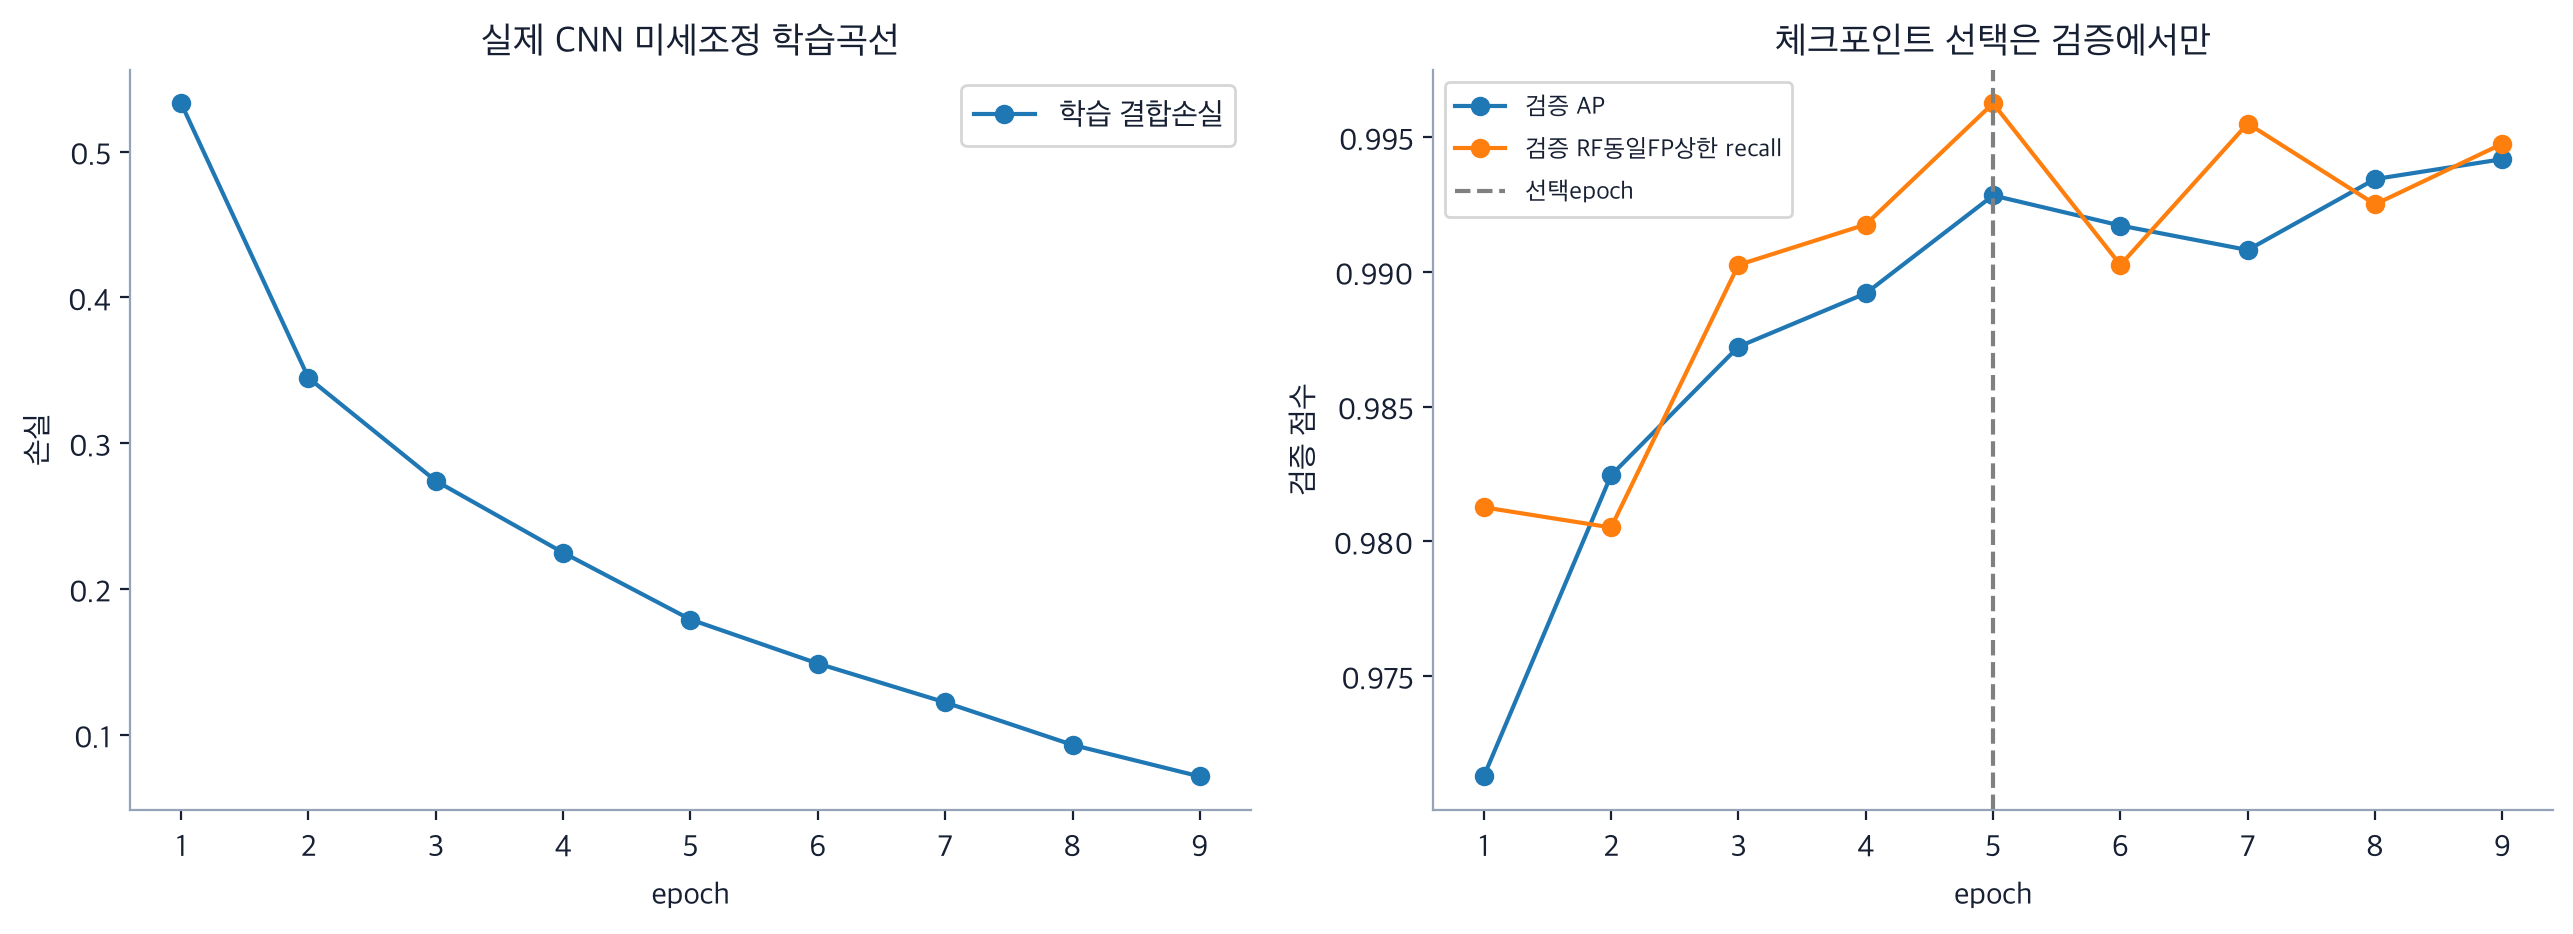

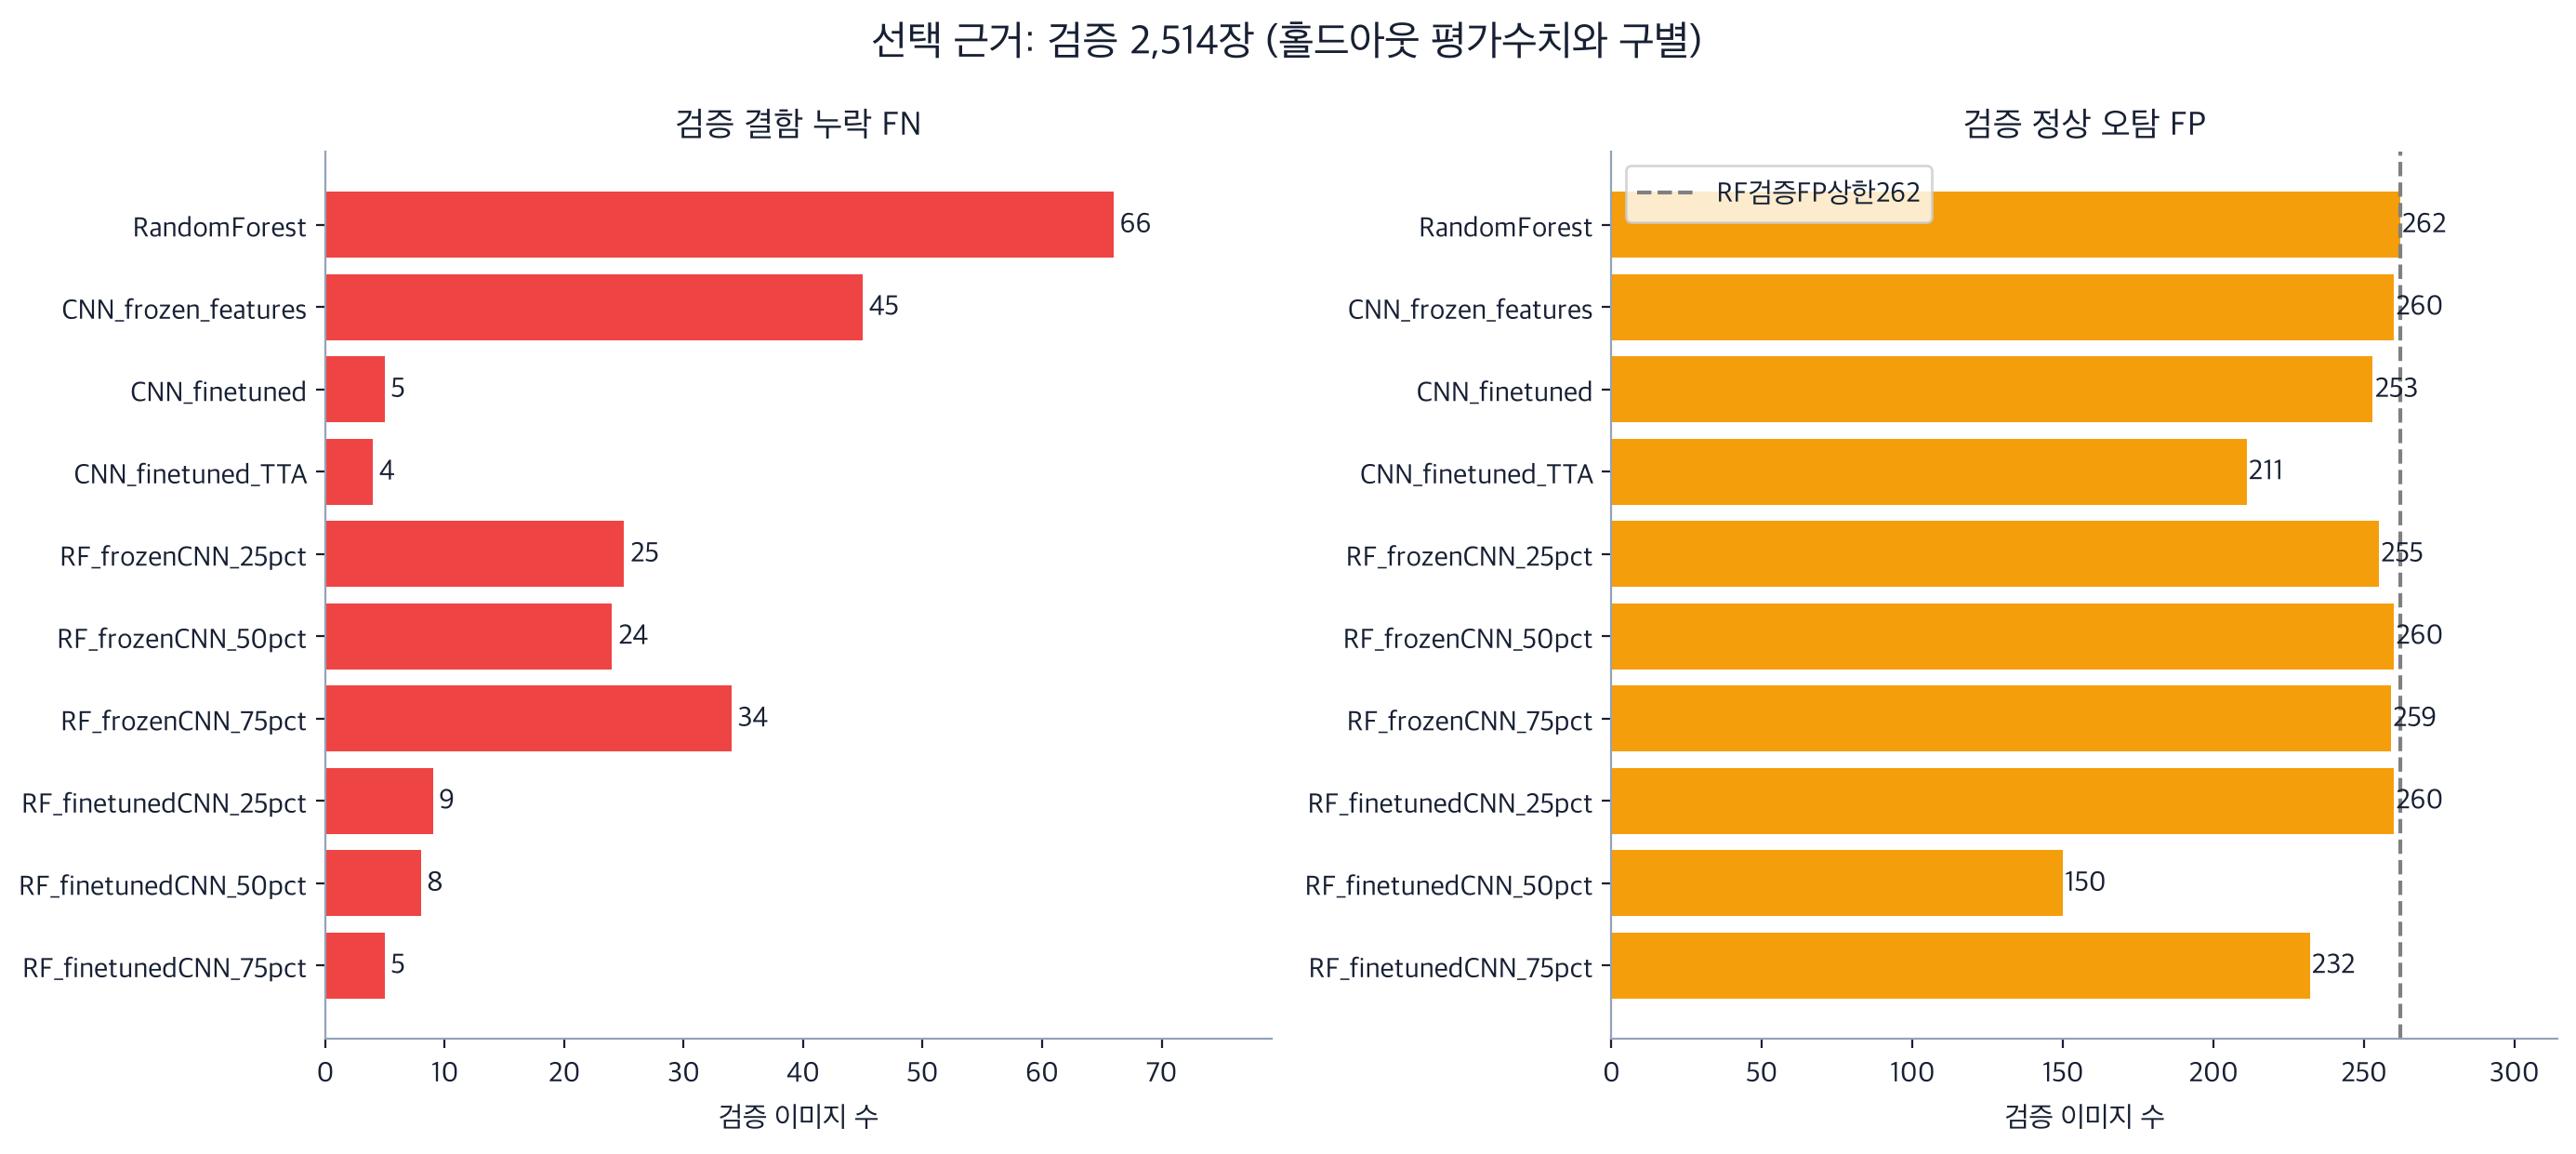

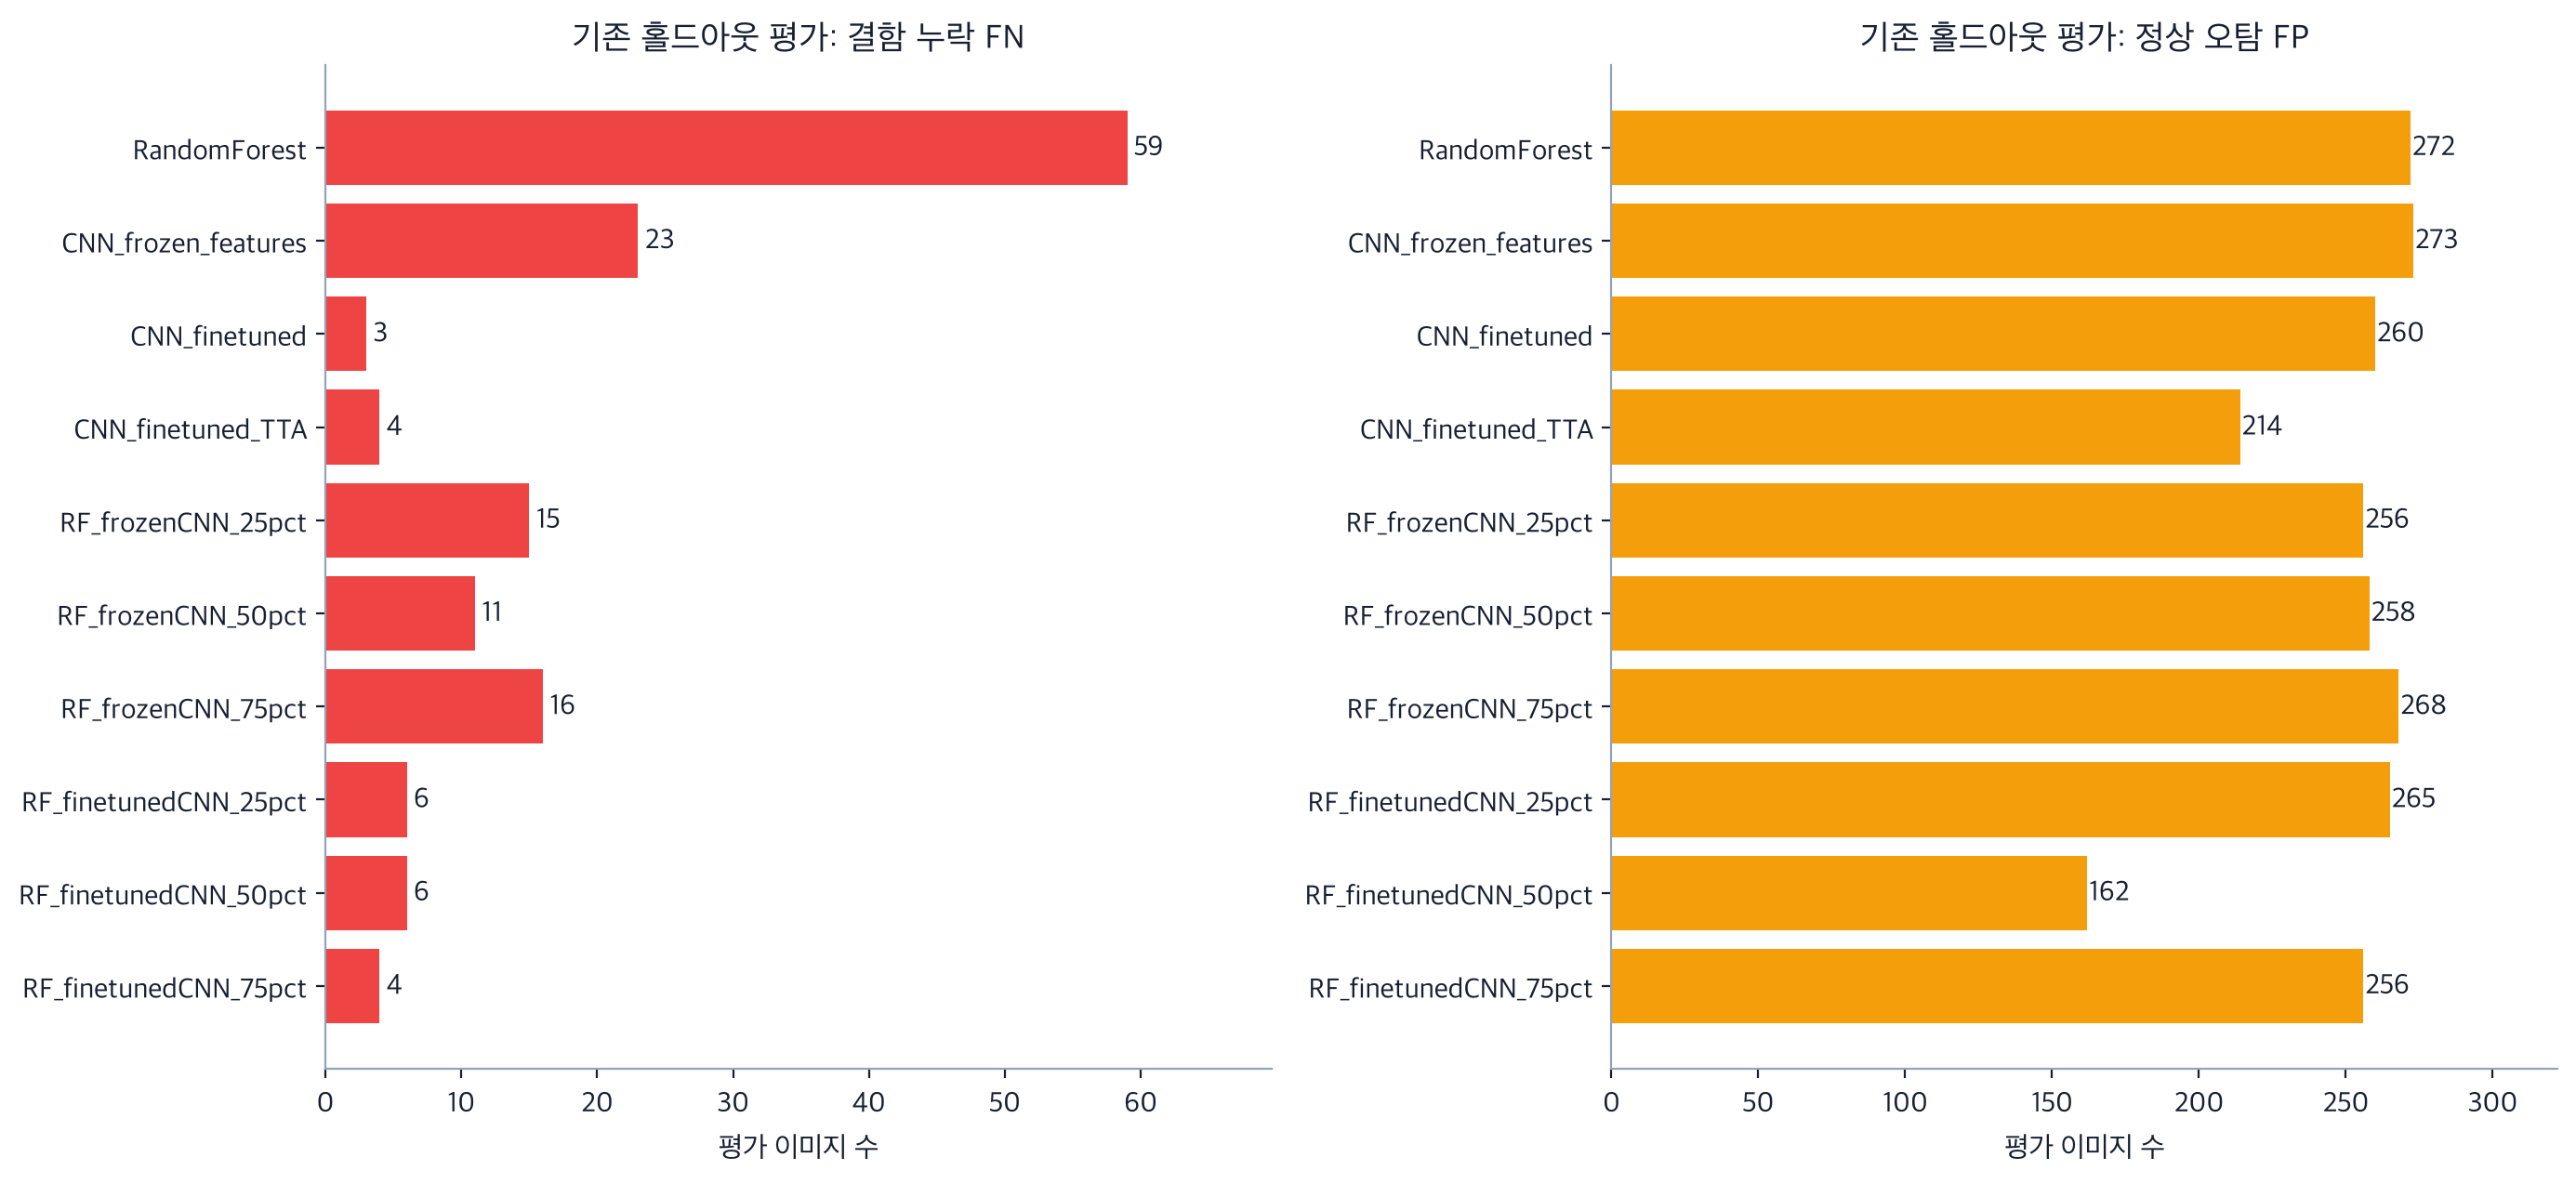

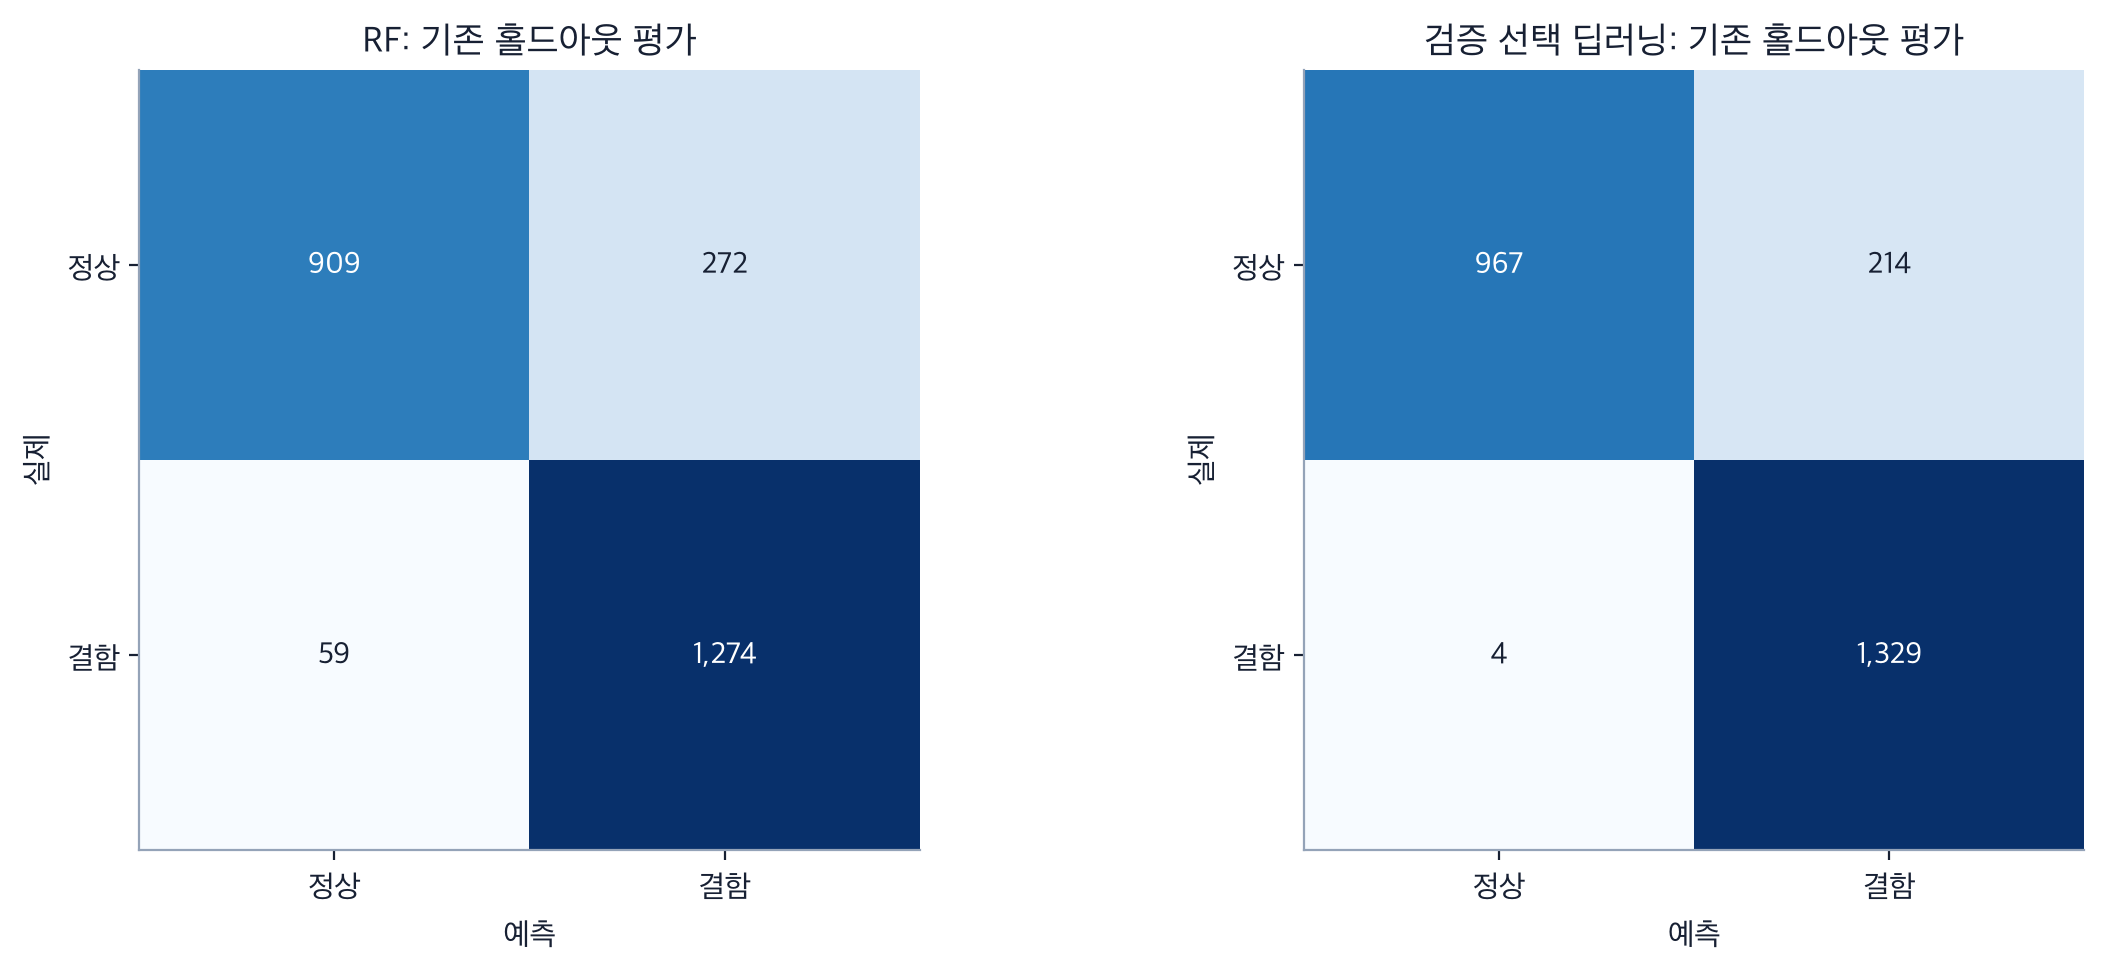

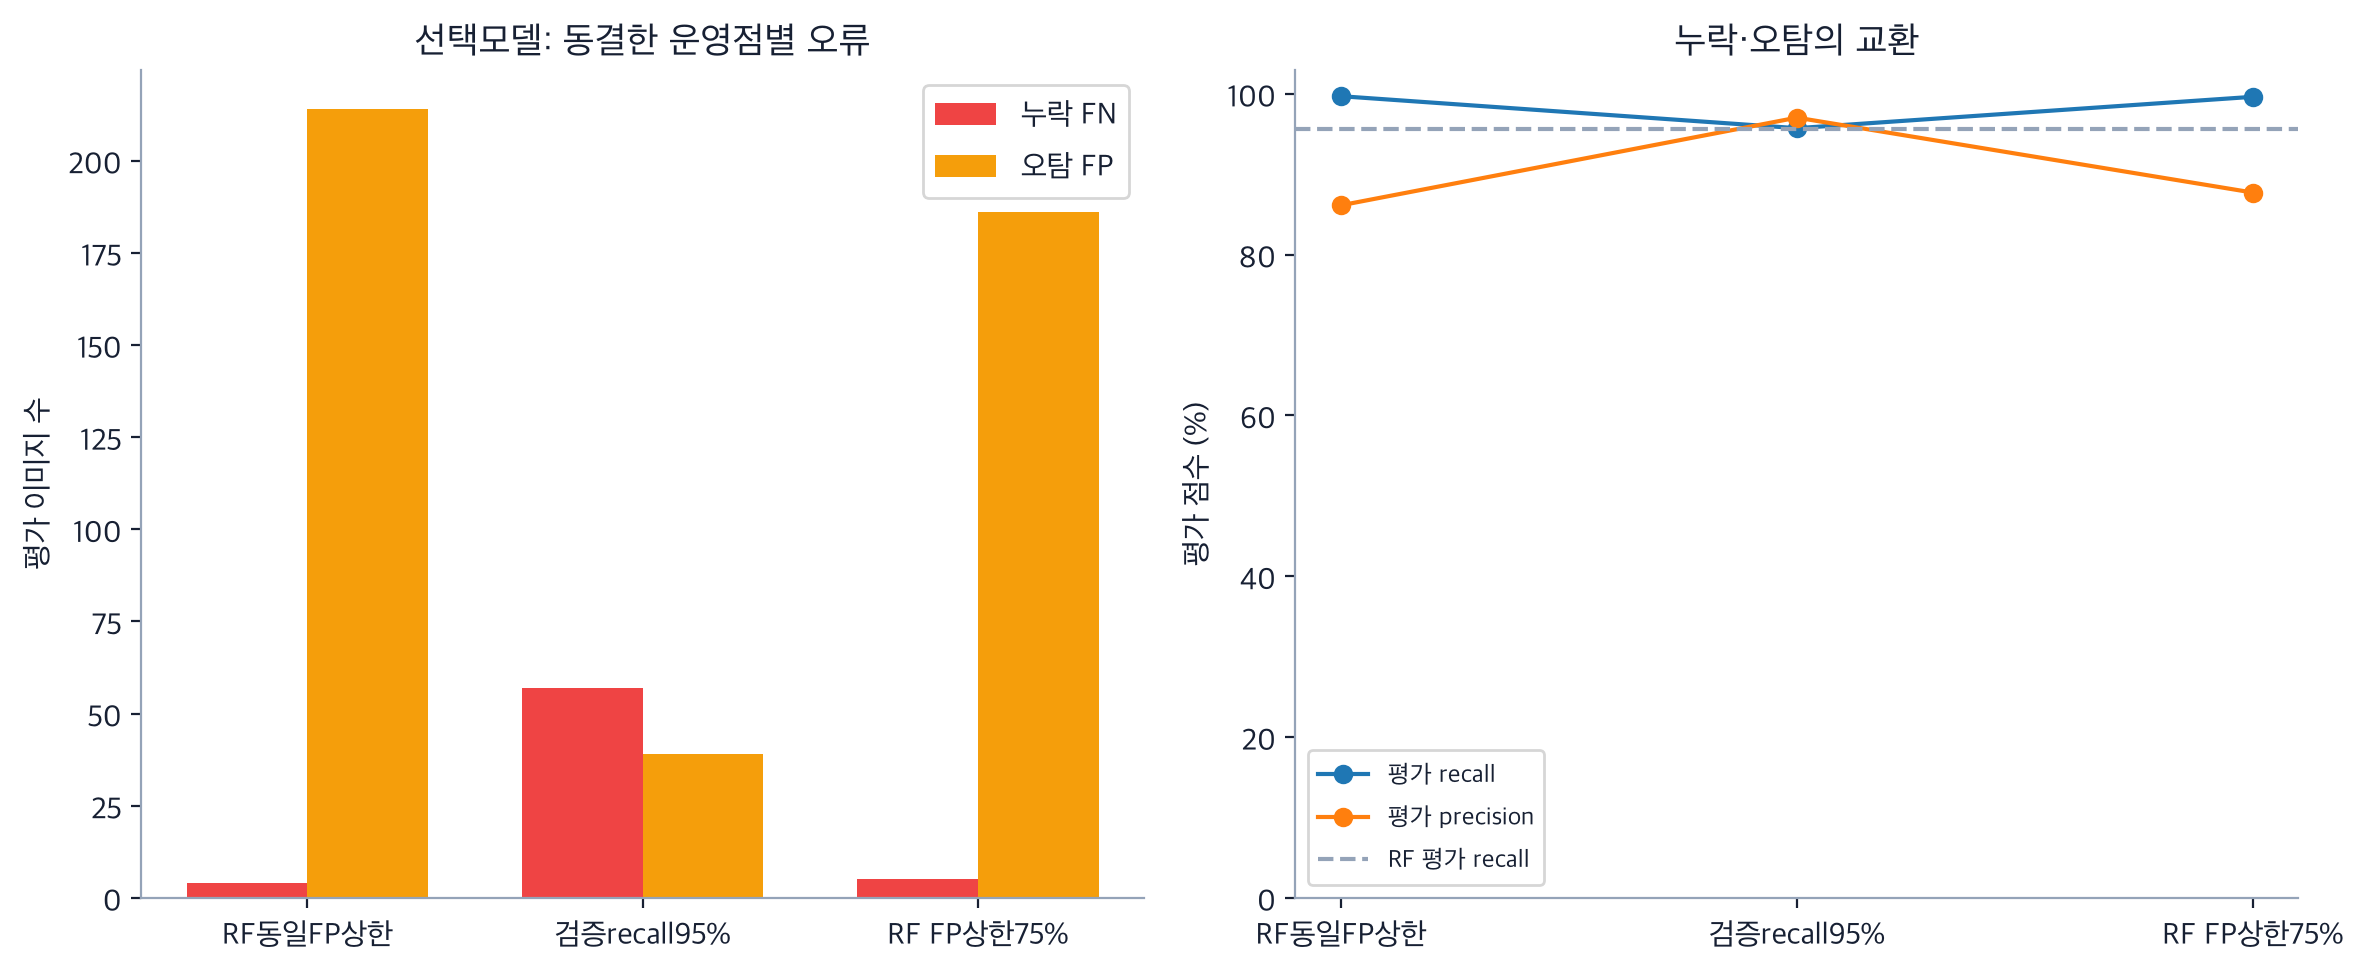

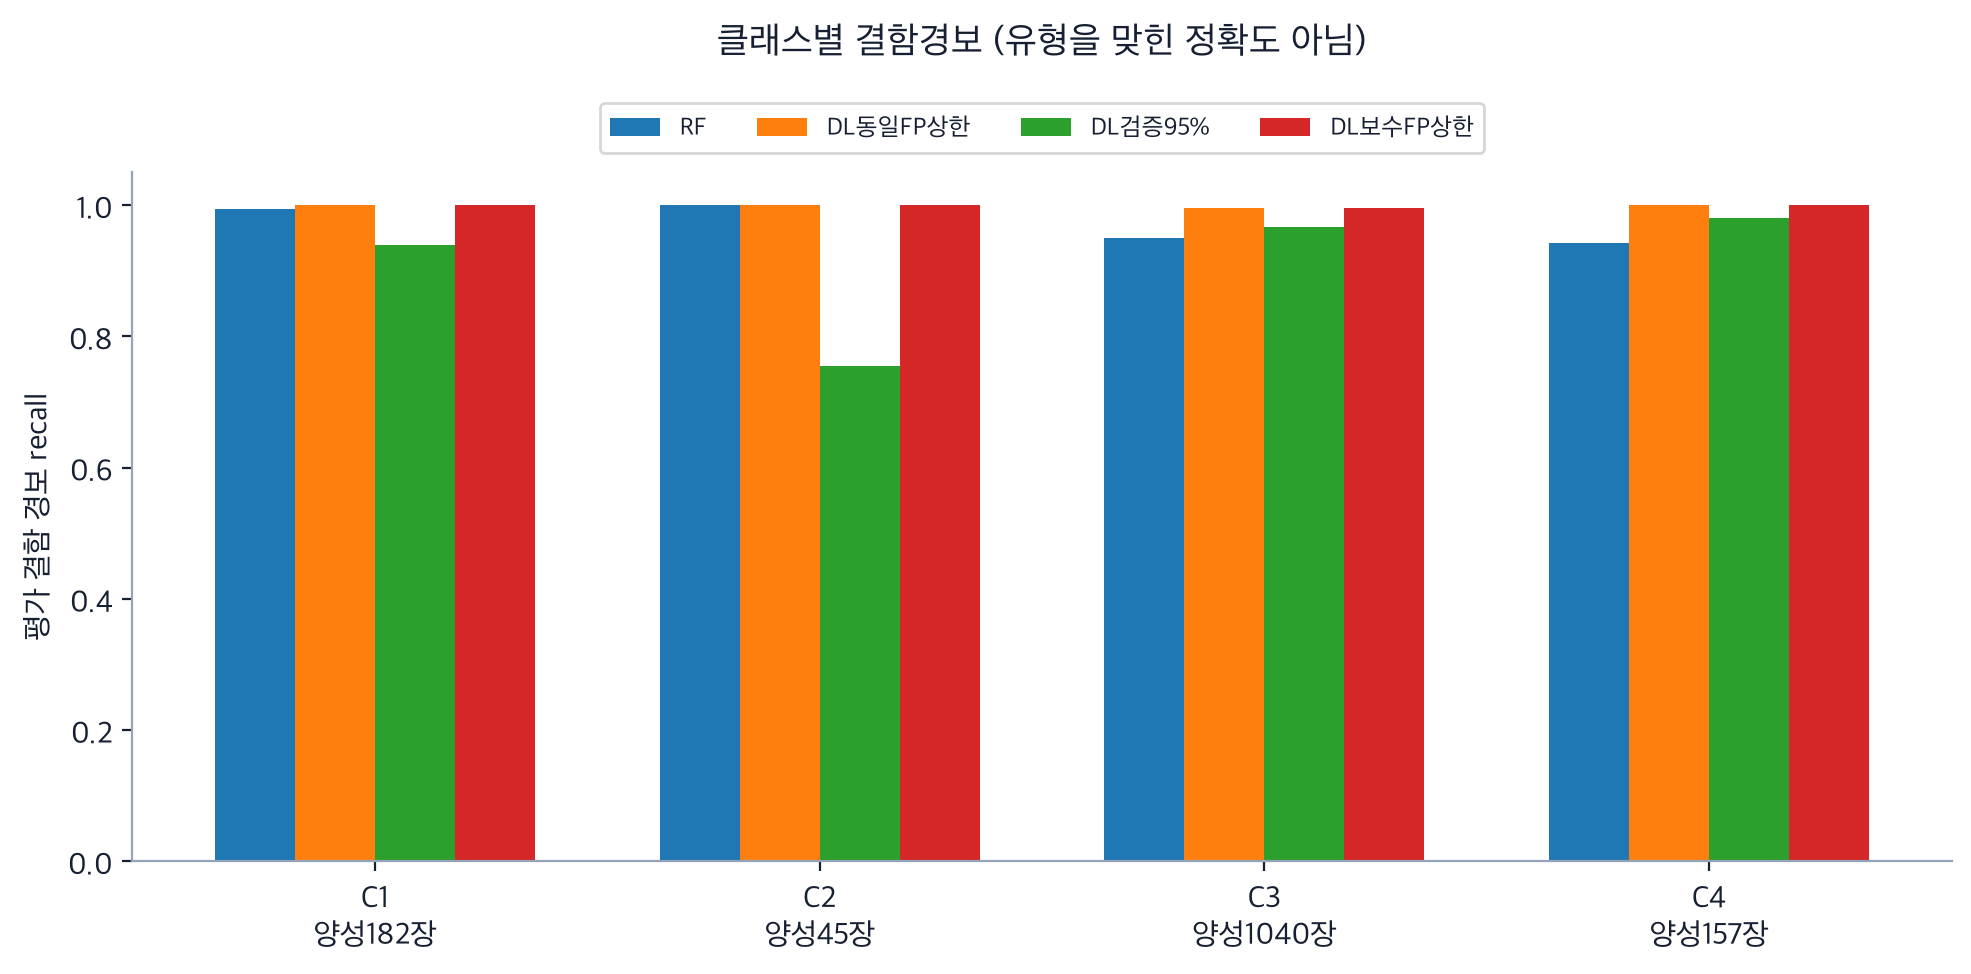

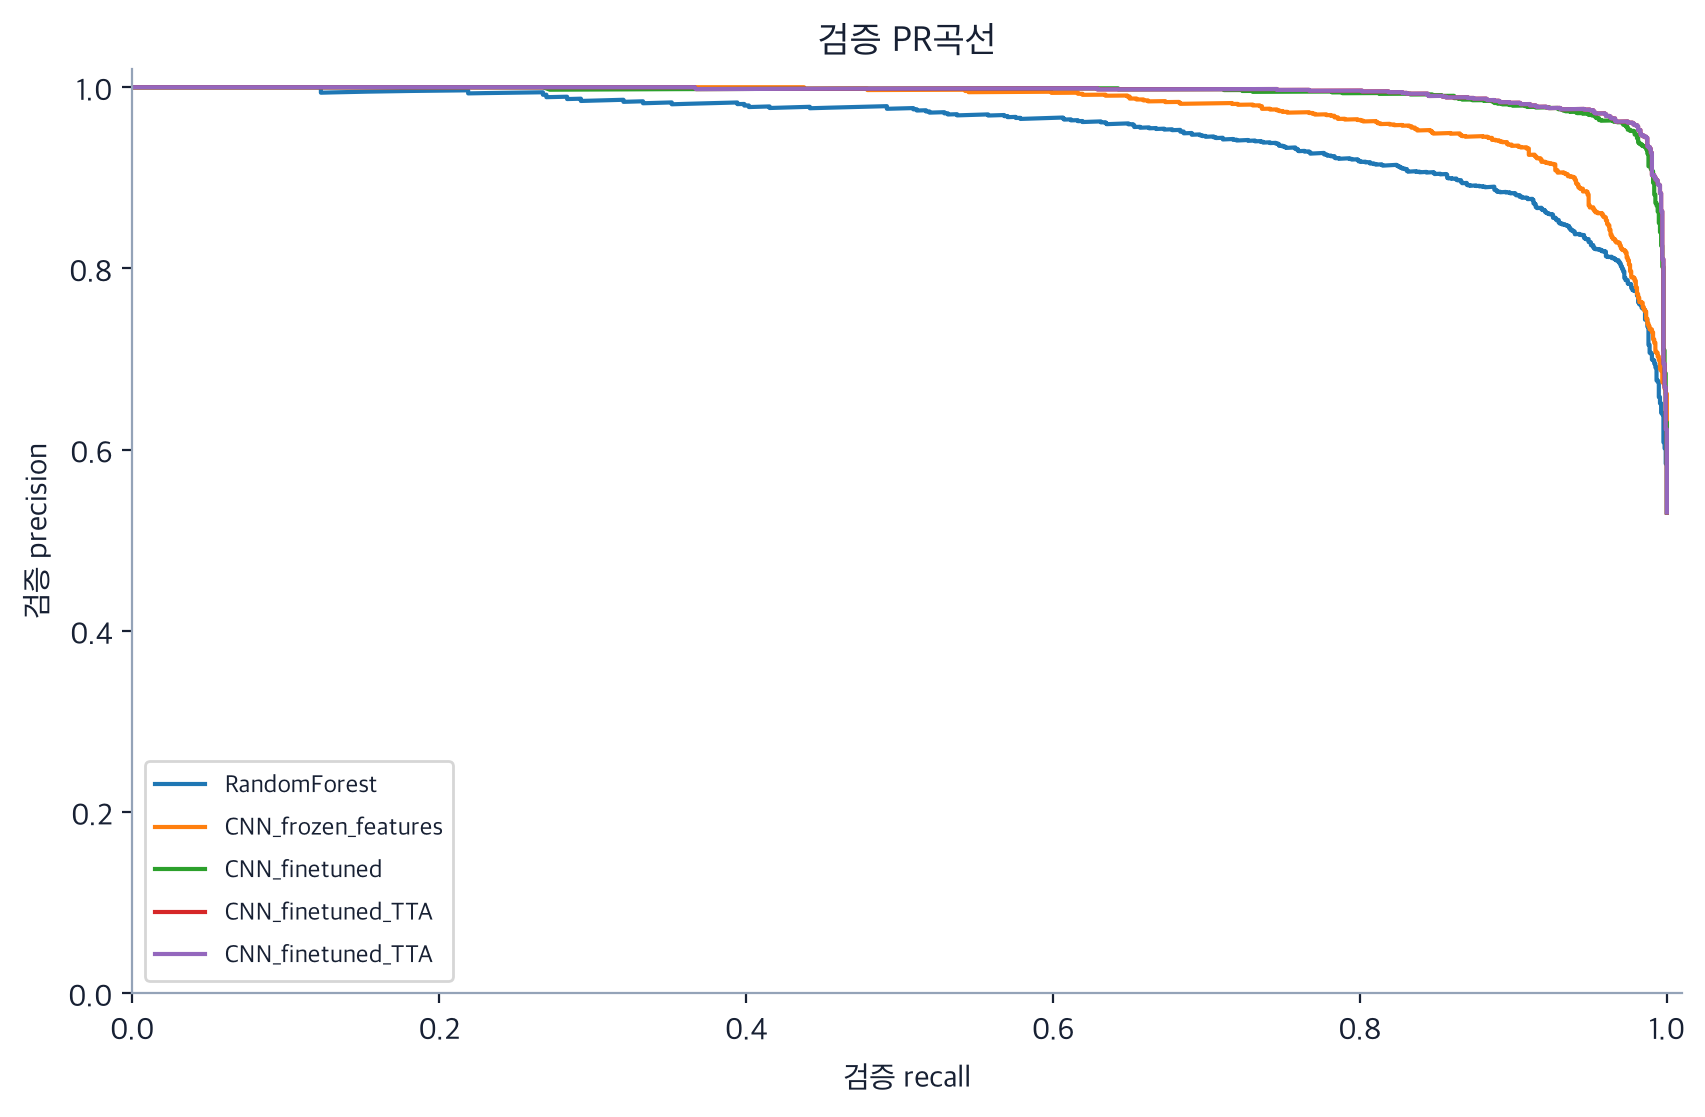

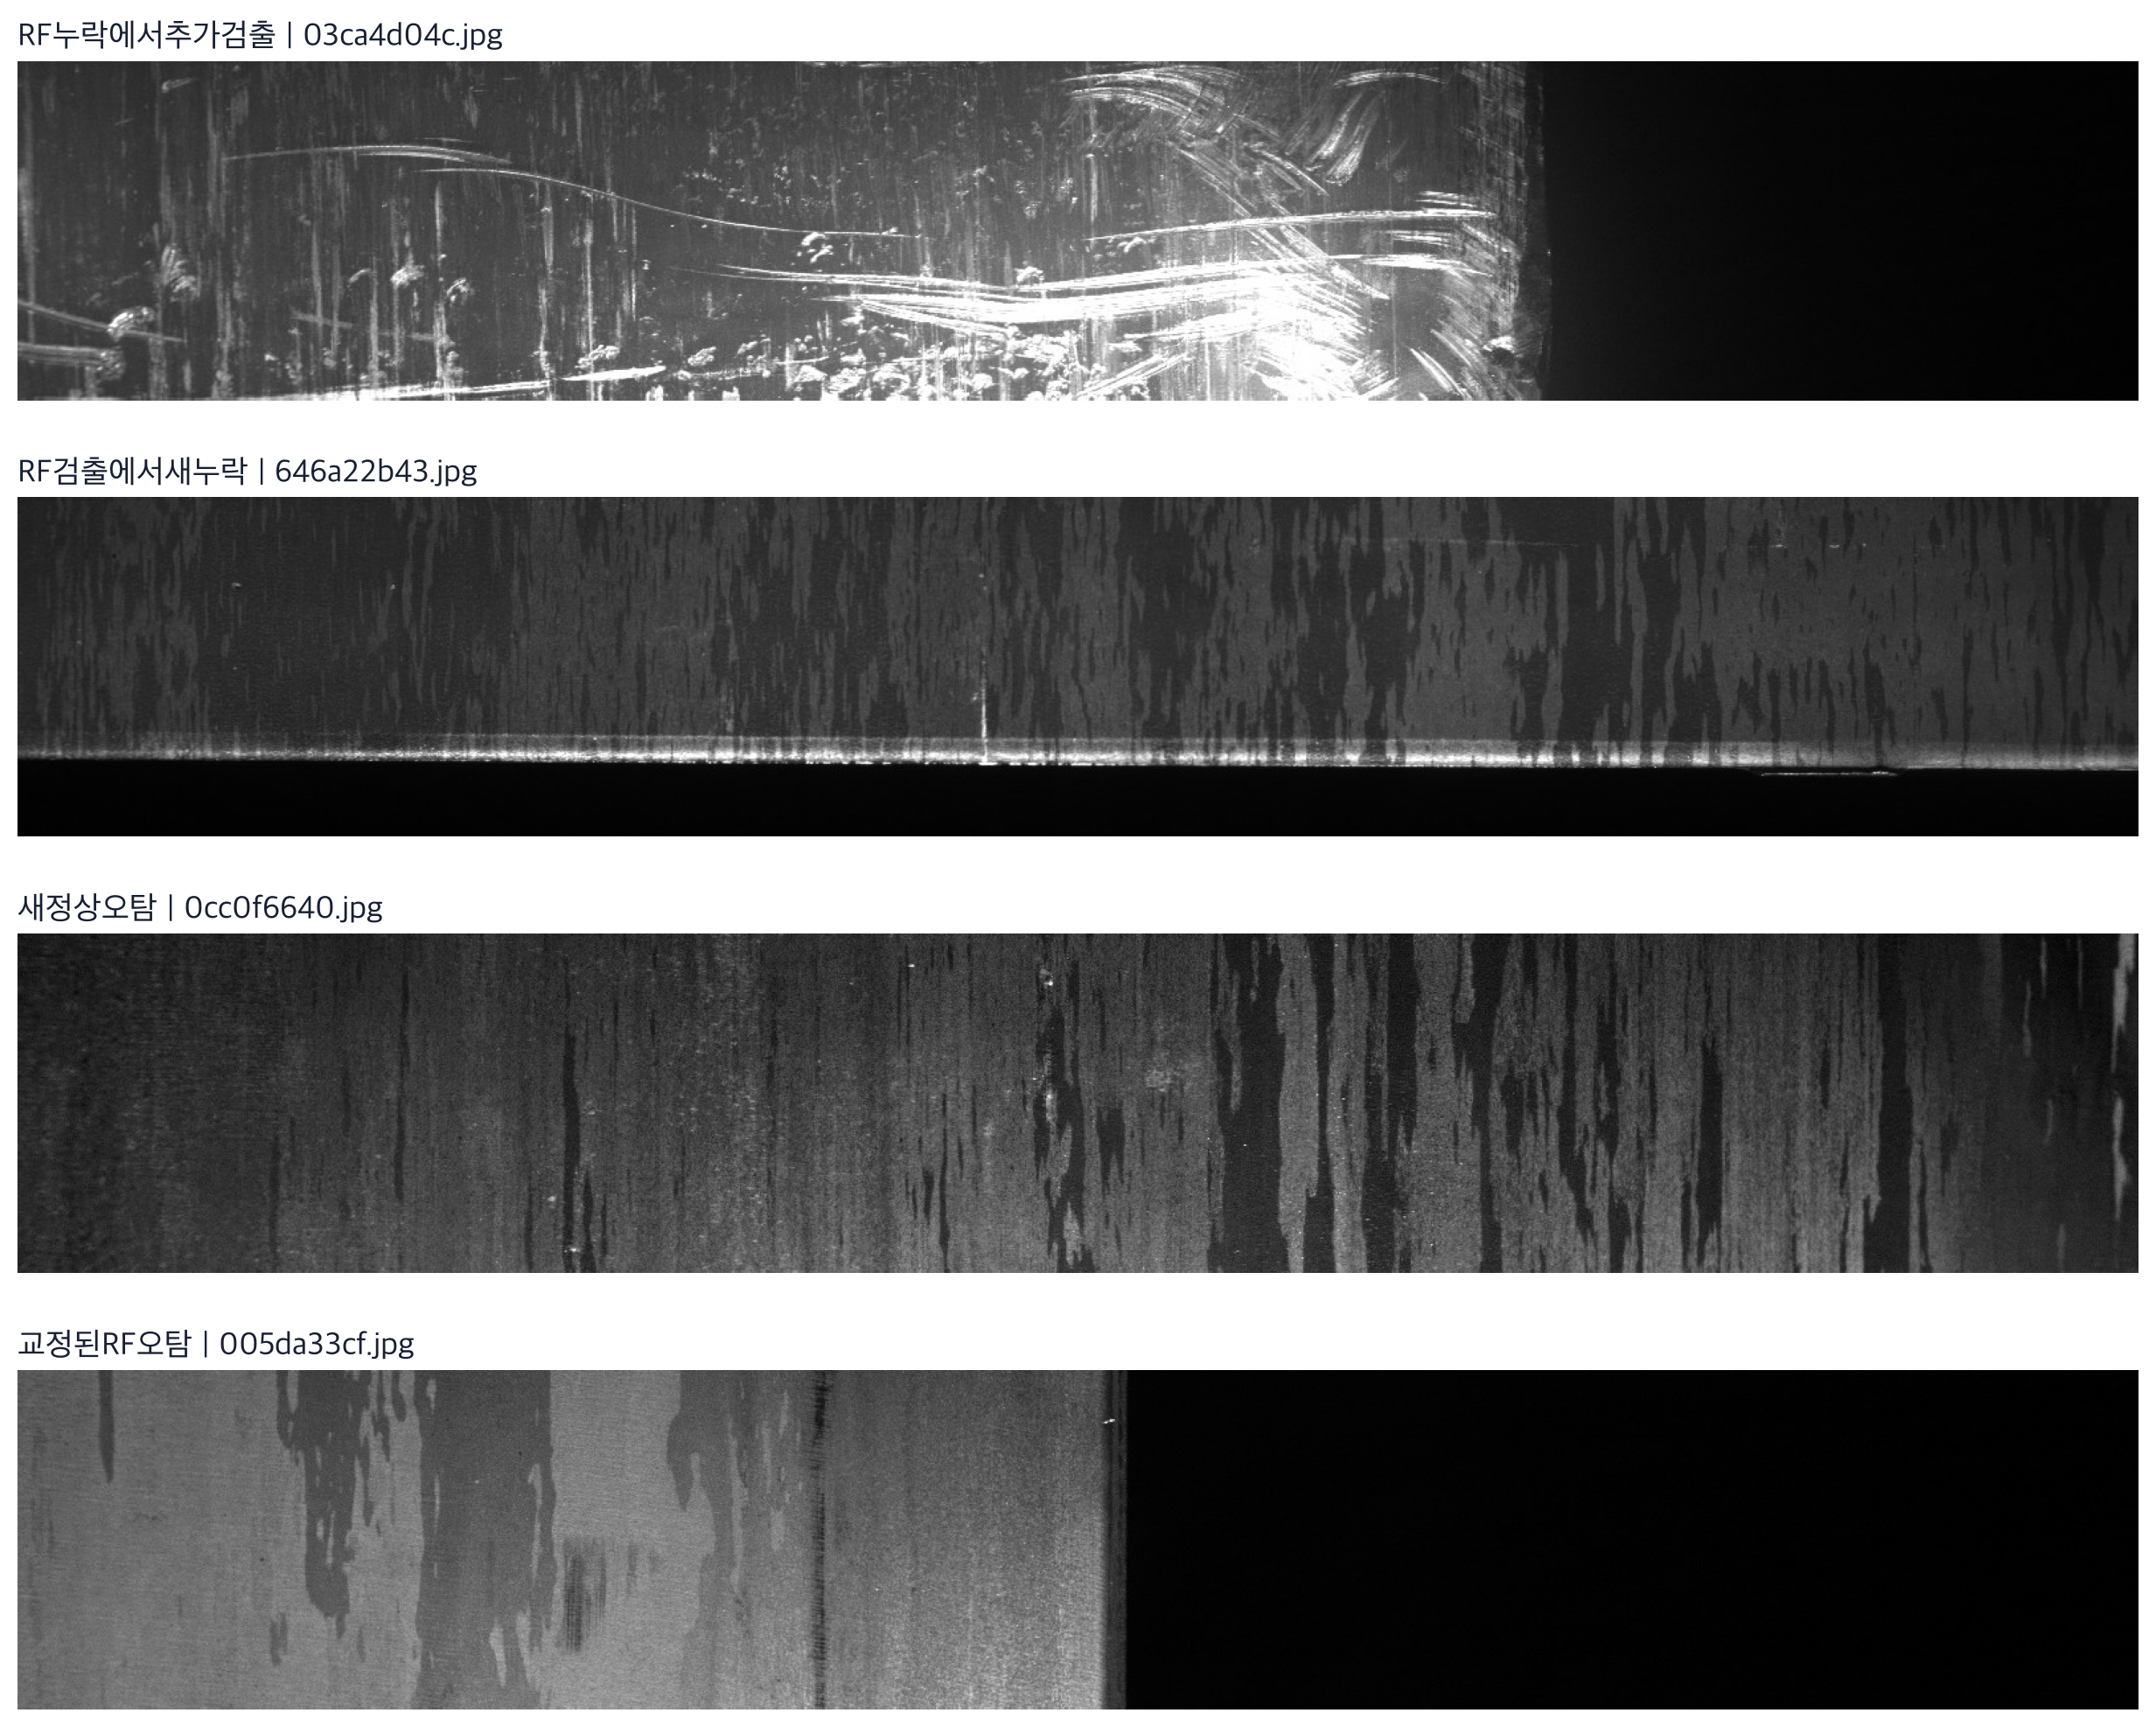

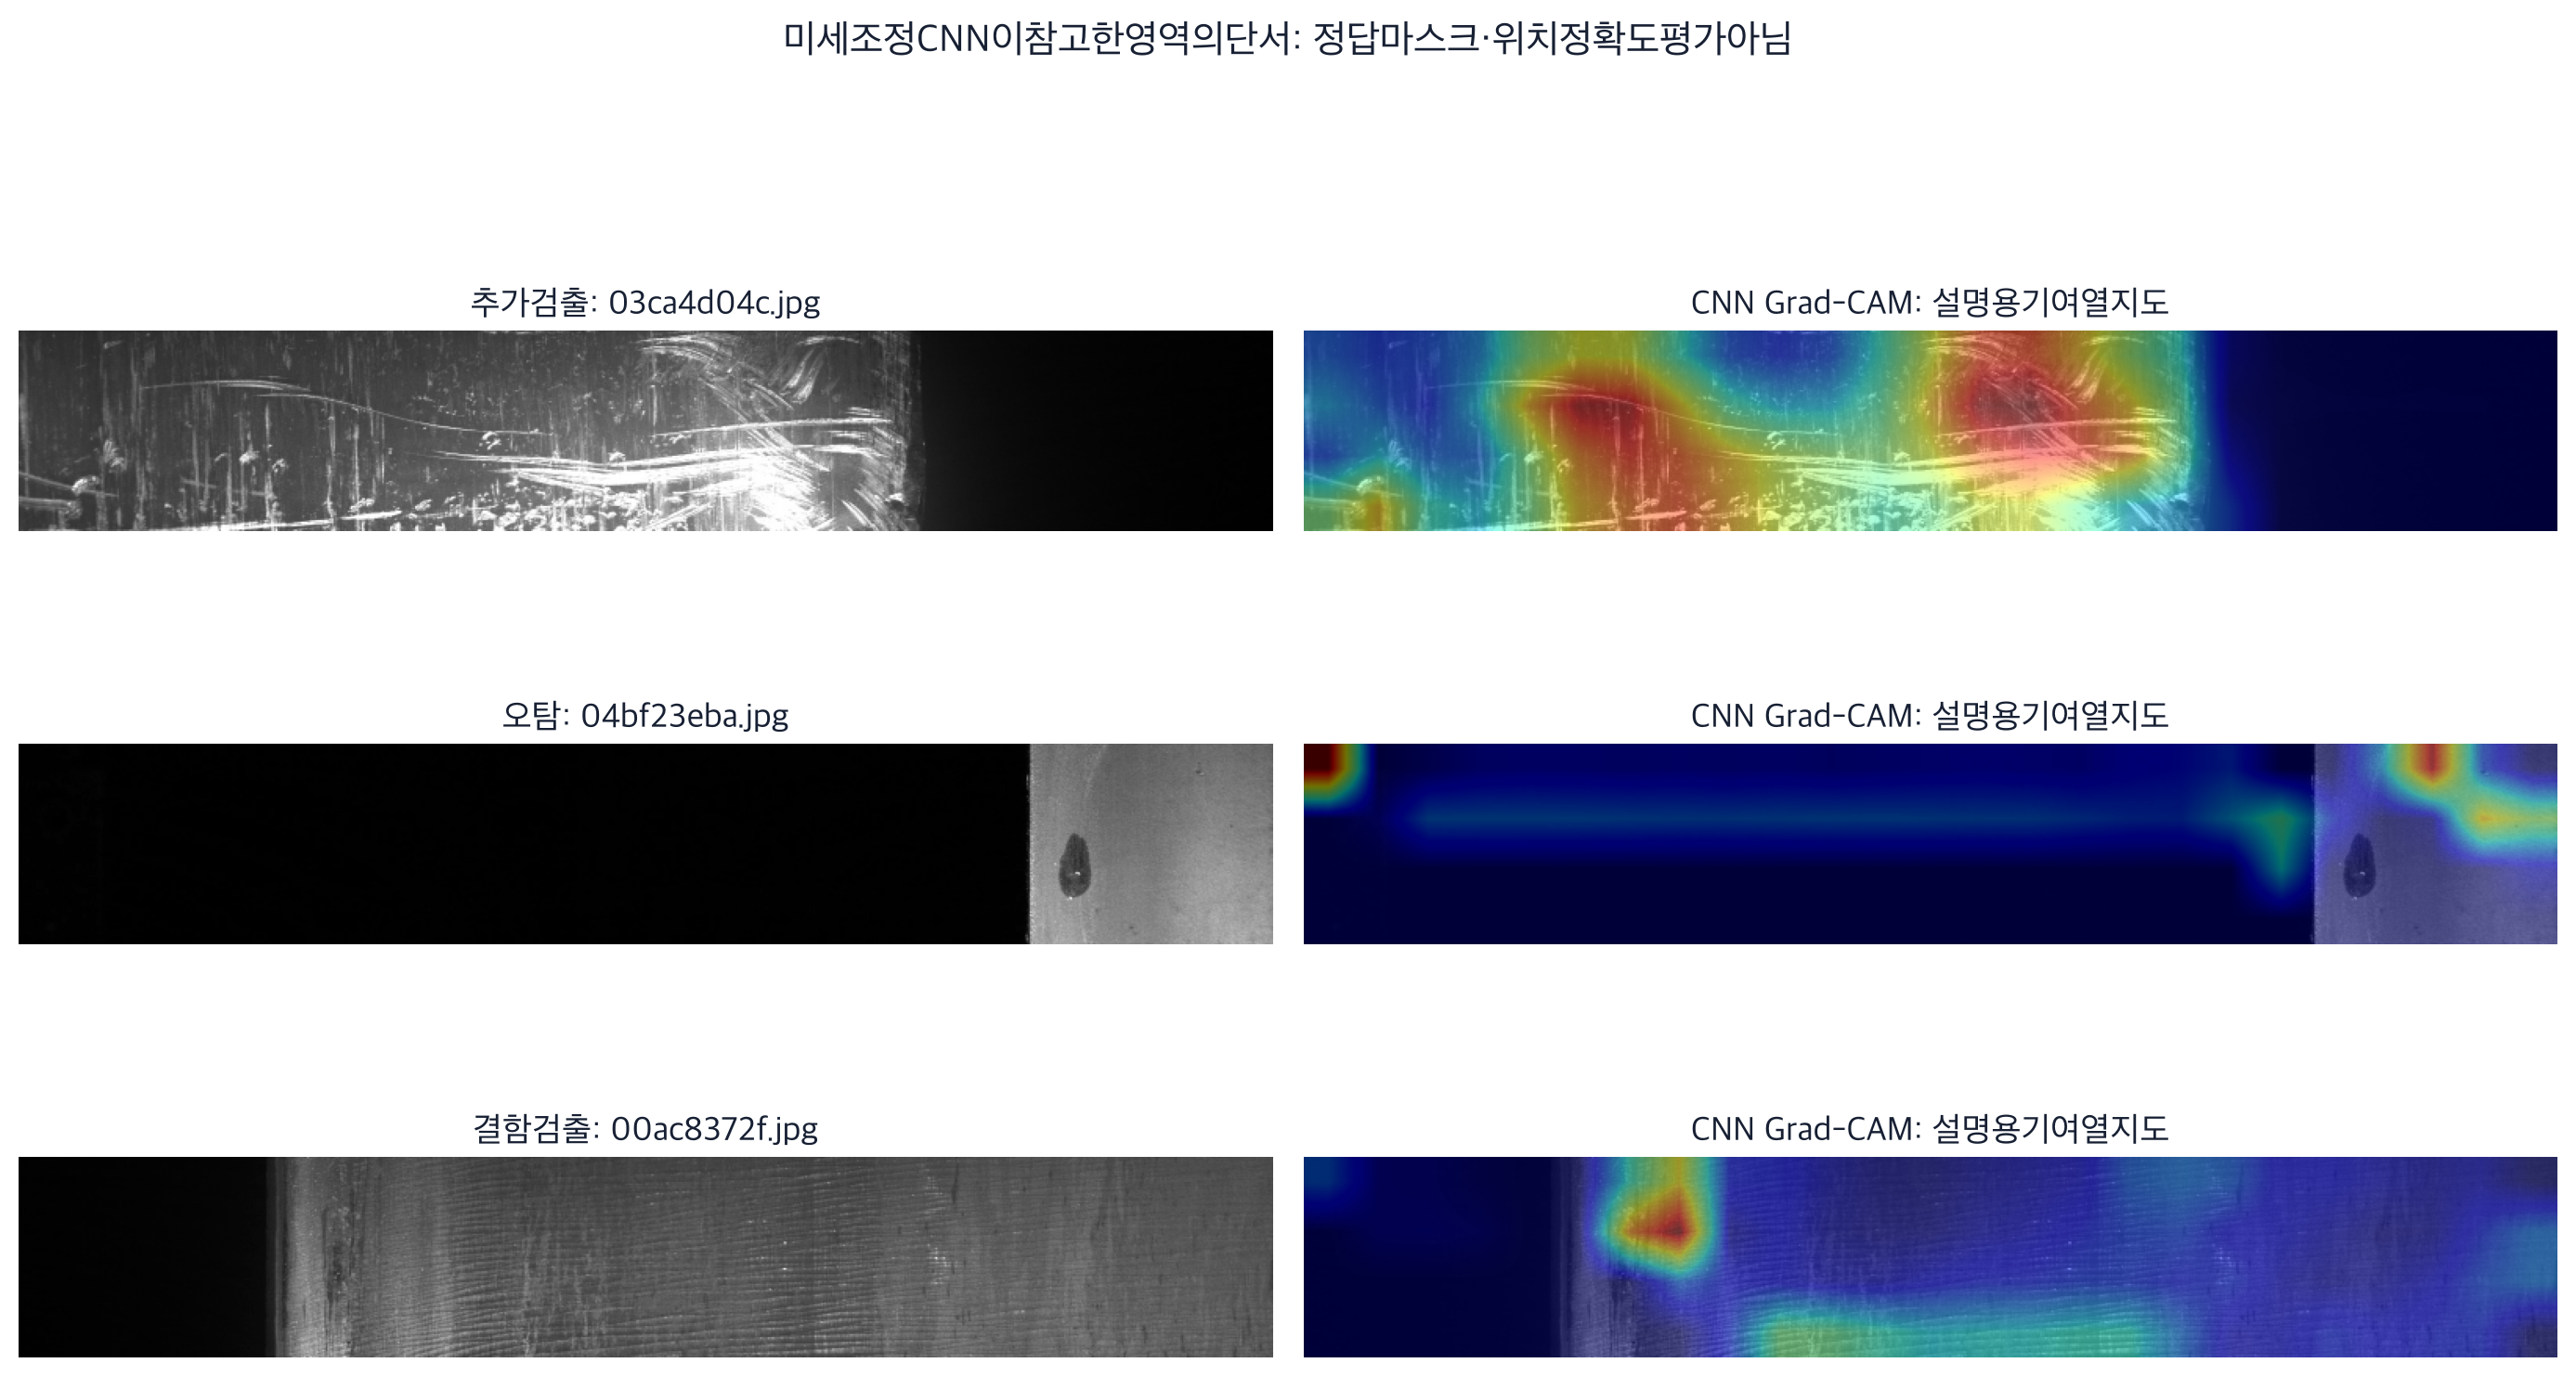

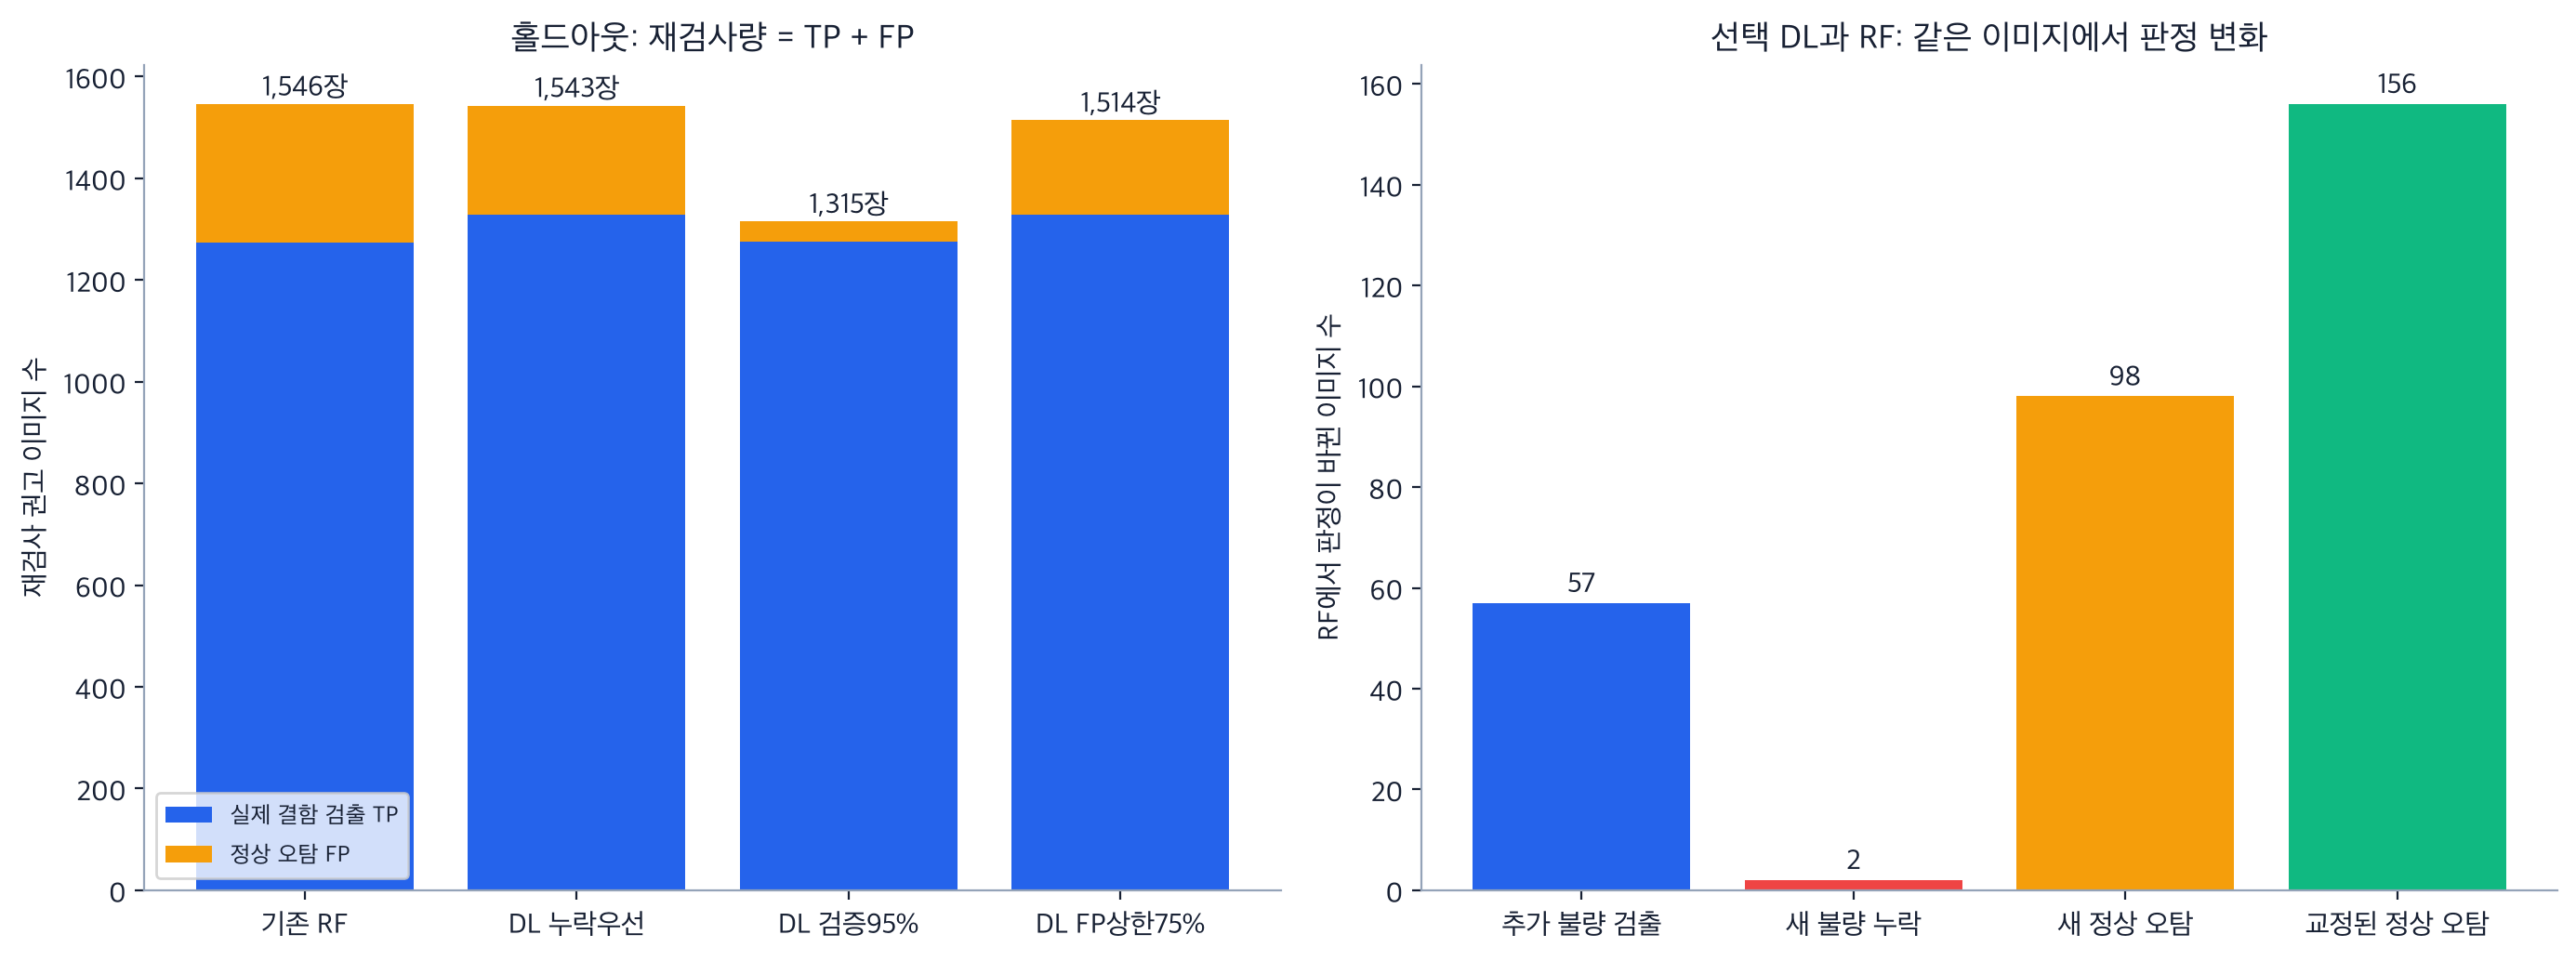

생성한 그림: 10


In [17]:
import importlib
import test1_deep_report as deep_report
importlib.reload(deep_report)
figure_count=deep_report.make_figures(data_dl)
deep_report.gradcam_examples(data_dl)
for name in ['01_training_validation_curves','02_validation_candidate_counts','03_holdout_candidate_counts','04_rf_deep_holdout_confusion','05_selected_operating_points','06_class_alarm_recall','07_validation_pr_curves','08_rf_deep_changed_examples','09_cnn_gradcam_explanations','10_reinspection_and_additional_detection']:
    path=OUT/'figures'/f'{name}.png'
    if path.exists():
        display(DisplayImage(filename=str(path)))
print('생성한 그림:',len(list((OUT/'figures').glob('*.png'))))

## 8. 라벨 없는 test_images 예측

검증에서 동결한 모델·판정 기준을 5,506장에 적용합니다. 정답이 없으므로 이 데이터의 recall·precision은 계산할 수 없습니다. 결과는 이미지 단위 결함 경보이며 픽셀 마스크/RLE 제출파일이 아닙니다.

In [14]:
importlib.reload(dl)
unlabeled_predictions = dl.predict_unlabeled(data_dl)
display(unlabeled_predictions.head())
print('총 이미지:',len(unlabeled_predictions))
print('운영점별 재검사 권고 수:')
print(unlabeled_predictions.filter(regex='_pred$').sum())

무라벨 이미지 준비 1,500/5,506
무라벨 이미지 준비 3,000/5,506
무라벨 이미지 준비 4,500/5,506
無라벨 test_images 예측저장: 5506 장. 성능평가나 픽셀분할 제출파일은 아님.


,ImageId,selected_score,RF_score,RF_original_pred,selected_RF_same_FP_budget_pred,selected_recall95_pred,selected_RF_FP_budget75pct_pred
0,0000f269f.jpg,0.887202,0.496045,1,1,1,1
1,000ccc2ac.jpg,0.021456,0.445887,1,0,0,0
2,002451917.jpg,0.997293,0.667703,1,1,1,1
3,003c5da97.jpg,1.000000,0.486672,1,1,1,1
4,0042e163f.jpg,1.000000,0.473982,1,1,1,1


총 이미지: 5506
운영점별 재검사 권고 수:
RF_original_pred                   4453
selected_RF_same_FP_budget_pred    4776
selected_recall95_pred             3086
selected_RF_FP_budget75pct_pred    4678
dtype: int64


## 9. 수치·원본 보존 확인 및 발표 자료 저장

기존 RF FN59/FP272 재현, 원본 파일 해시, 30개 평가 행의 수치, 검증에서 고정한 임계값, 체크포인트 재로딩 예측을 확인합니다. 검증과 평가 수치를 분리한 표·클래스별 결과·설명 보고서를 저장합니다.

In [18]:
importlib.reload(deep_report)
verification = deep_report.verify_results(data_dl)
presentation_comparison, presentation_class_results = deep_report.write_report(data_dl)
display(presentation_comparison)
display(presentation_class_results)
print('보고서:', OUT/'REPORT.html')
print('원본 보존:', verification['protected_files_unchanged'])

검증 완료: {'protected_files_unchanged': True, 'protected_file_count': 45, 'holdout_csv_metrics_verified': 30, 'validation_selected_before_holdout': True, 'same_image_splits': True, 'RF_FN59_FP272_reproduced': True, 'checkpoint_score_max_abs_error': 0.0, 'png_figures': 10, 'unlabeled_prediction_count': 5506}
발표용 보고서: /Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main/deep_learning_outputs/REPORT.html


,운영 방식,평가 recall,평가 precision,누락 FN,오탐 FP,재검사 권고 TP+FP,검증에서 고정한 threshold
0,기존 RandomForest,95.57%,82.41%,59,272,1546,0.381439730
1,DL 누락 우선 (주 분석),99.70%,86.13%,4,214,1543,0.053468388
2,DL 검증 recall95%,95.72%,97.03%,57,39,1315,0.856613517
3,DL RF FP상한75%,99.62%,87.71%,5,186,1514,0.087509729


,클래스,평가 양성 이미지,RF 경보 recall,DL 경보 recall,DL 누락,DL 검증95% 기준 recall,DL FP상한75% 기준 recall
0,1,182,99.45%,100.00%,0,93.96%,100.00%
1,2,45,100.00%,100.00%,0,75.56%,100.00%
2,3,1040,95.00%,99.62%,4,96.63%,99.52%
3,4,157,94.27%,100.00%,0,98.09%,100.00%


보고서: /Users/yeongjunna/Projects/severstal-steel-defect-detection/comvisionPJ-main/deep_learning_outputs/REPORT.html
원본 보존: True


## 10. 결과를 발표할 때의 해석

**선택 모델: 사전학습 ResNet18 미세조정 + 원본/좌우반전 점수 평균(TTA). RF 결합 없이 CNN이 선택되었습니다.**

- CNN은 밝기·엣지 통계를 사람이 39개로 정해주는 대신, 이미지 안의 질감·선·형태를 학습합니다. 전체 영상을 800×128로 넣고 평균·최댓값 특징을 함께 사용해 국소 결함을 남겼습니다.
- 주 분석은 검증에서 RF 오탐 262장 이하라는 조건 안에서 recall을 최대화했습니다. 검증은 **FN4·FP211**, 같은 기준을 고정한 홀드아웃 평가는 **FN4·FP214**입니다. 숫자가 다른 것은 데이터 분할이 다르기 때문입니다.
- 기존 RF의 홀드아웃은 **FN59·FP272 / recall95.57%**입니다. CNN 주 분석은 **FN4·FP214 / recall99.70%**로 누락과 오탐이 모두 감소했습니다. 여기서 99.70%는 전체 정확도가 아니라 실제 불량 중 검출한 비율입니다.
- RF가 놓친 불량 57장을 추가로 찾았지만, RF가 맞힌 2장은 새로 놓쳐 순수 누락 감소는 55장입니다. 기존 RF 오탐 156장을 교정하고 새 오탐 98장이 생겨 순수 오탐 감소는 58장입니다.
- 재검사 권고량은 **TP+FP**입니다. 주 분석은 1,546→1,543장으로 거의 같지만, 그 안에서 실제 불량 검출 비중이 커졌습니다.
- 검증 recall95%를 목표로 미리 고정한 별도 운영점은 평가 **FN57·FP39 / recall95.72%**입니다. 누락 우선 운영과 재검사 부담을 줄이는 운영을 구별해 설명할 수 있습니다. 주 모델 선택을 평가 결과로 바꾸지는 않았습니다.

이번에는 학습 7,540장만 사용했고, 모델·epoch·threshold는 검증으로 정했습니다. 다만 평가 분할 자체는 이전 분석에서 이미 본 것이므로 **기존 분할의 후속 비교**입니다. 새로운 생산 데이터에서 같은 수준이 유지된다는 보장은 없습니다.

보고서와 그림은 `deep_learning_outputs/REPORT.html`, `deep_learning_outputs/figures/`에 저장됩니다. 기존 RF 노트북·모델·결과는 보존합니다.

### 희소 클래스도 함께 확인하기

검증95% 운영점은 전체 평가 recall이 **95.72%**이지만 클래스2의 경보 recall은 **75.56%(34/45장)**입니다. 전체 점수만 보면 이 차이를 놓칠 수 있습니다. 누락 우선 주 분석 기준은 클래스2 **45/45장**을 검출했습니다. 발표에서는 전체 recall과 클래스별 경보 recall을 함께 보여주는 것이 좋습니다.